# Gradient Descent refined search on Fritz

Run this notebook only after inspecting `results/gd_coarse/best_by_config.csv`. Fill in the refined grid manually in the dedicated configuration cell below.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from als import predict_pairs_numba_kernel
from evaluation import rmse_from_predictions
from gd_sparce_numba import gradient_descent_numba

In [2]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "ml-latest"
COARSE_RESULTS_DIR = PROJECT_ROOT / "results" / "gd_coarse"
RESULTS_DIR = PROJECT_ROOT / "results" / "gd_refined"
HISTORIES_DIR = RESULTS_DIR / "histories"
HISTORIES_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROCESSED_DIR / "train_ratings.csv")
user_map = pd.read_csv(PROCESSED_DIR / "user_map.csv")
movie_map = pd.read_csv(PROCESSED_DIR / "movie_map.csv")

n_users = len(user_map)
n_movies = len(movie_map)

train_fit_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

val_user_idx = val_df["user_idx"].to_numpy(dtype=np.int64)
val_movie_idx = val_df["movie_idx"].to_numpy(dtype=np.int64)
val_ratings = val_df["rating"].to_numpy(dtype=np.float64)

print("Train fit shape:", train_fit_df.shape)
print("Validation shape:", val_df.shape)
print("Number of users:", n_users)
print("Number of movies:", n_movies)

Train fit shape: (21652583, 6)
Validation shape: (5413146, 6)
Number of users: 330975
Number of movies: 83239


In [3]:
coarse_results_path = COARSE_RESULTS_DIR / "best_by_config.csv"
if not coarse_results_path.exists():
    raise FileNotFoundError(
        "Run the coarse-search Slurm job before the refined search: "
        f"{coarse_results_path}"
    )

coarse_best_by_config = pd.read_csv(coarse_results_path)
print("Best coarse-search configurations:")
display(coarse_best_by_config.head(12))

Best coarse-search configurations:


,iteration,rank,eta,reg,init_scale,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,config_seconds
0,25,30,0.0003,0.1,0.01,1.218562e+07,1.060920,1.060920,1.865692e-03,1.060881,102.355940
1,25,30,0.0003,1.0,0.01,1.218699e+07,1.060952,1.060952,1.842506e-03,1.060910,102.440058
2,25,20,0.0003,0.1,0.01,1.220510e+07,1.061769,1.061769,1.350270e-03,1.061654,76.326682
3,25,20,0.0003,1.0,0.01,1.220606e+07,1.061792,1.061792,1.333322e-03,1.061675,76.241398
4,25,10,0.0003,0.1,0.01,1.222784e+07,1.062759,1.062759,7.446042e-04,1.062560,58.493366
5,25,10,0.0003,1.0,0.01,1.222835e+07,1.062771,1.062771,7.352043e-04,1.062572,58.406551
6,25,30,0.0001,0.1,0.01,1.225487e+07,1.063931,1.063931,2.385483e-06,1.063654,102.543836
7,25,30,0.0001,1.0,0.01,1.225543e+07,1.063931,1.063931,2.372626e-06,1.063654,102.509578
8,25,20,0.0001,0.1,0.01,1.225500e+07,1.063937,1.063937,1.647629e-06,1.063656,76.234249
9,25,20,0.0001,1.0,0.01,1.225537e+07,1.063937,1.063937,1.638709e-06,1.063656,76.335935


In [4]:
def gd_validation_metrics(U, V, global_mean):
    predictions = predict_pairs_numba_kernel(
        U,
        V,
        val_user_idx,
        val_movie_idx,
        global_mean,
    )

    if not np.all(np.isfinite(predictions)):
        raise FloatingPointError(
            "Non-finite validation predictions; configuration diverged"
        )

    predictions = np.clip(predictions, 0.5, 5.0)

    return {
        "val_rmse": rmse_from_predictions(val_ratings, predictions),
    }

## Define the refined grid manually

In [ ]:
refined_rank_values = [30, 50]
refined_eta_values = [3e-4, 1e-3, 3e-3]
refined_reg_values = [0.1, 1.0]
refined_init_scale_values = [0.01, 0.05]

refined_grid_max_iter = 150
finalist_max_iter = 300

print("Refined configurations:",
      len(refined_rank_values)
      * len(refined_eta_values)
      * len(refined_reg_values)
      * len(refined_init_scale_values))

Refined configurations: 24


## Refined search

In [6]:
warmup_result = gradient_descent_numba(
    train_fit_df.iloc[:1_000],
    n_users=n_users,
    n_movies=n_movies,
    rank=refined_rank_values[0],
    eta=refined_eta_values[0],
    reg=refined_reg_values[0],
    n_iter=1,
    init_scale=refined_init_scale_values[0],
    random_state=42,
    objective_tol=None,
)
del warmup_result

refined_histories = []
refined_failed_configs = []
refined_total_configs = (
    len(refined_rank_values)
    * len(refined_eta_values)
    * len(refined_reg_values)
    * len(refined_init_scale_values)
)
refined_config_number = 0
refined_search_start = perf_counter()

for rank in refined_rank_values:
    for eta in refined_eta_values:
        for reg in refined_reg_values:
            for init_scale in refined_init_scale_values:
                refined_config_number += 1
                history_path = HISTORIES_DIR / (
                    f"rank-{rank}_eta-{eta:g}_reg-{reg:g}_init-{init_scale:g}.csv"
                )
                print(
                    f"[{refined_config_number}/{refined_total_configs}] "
                    f"rank={rank}, eta={eta}, reg={reg}, init_scale={init_scale}"
                )

                if history_path.exists():
                    print("  using saved history")
                    refined_histories.append(pd.read_csv(history_path))
                    continue

                config_start = perf_counter()
                try:
                    _, _, _, history_df = gradient_descent_numba(
                        train_fit_df,
                        n_users=n_users,
                        n_movies=n_movies,
                        rank=rank,
                        eta=eta,
                        reg=reg,
                        n_iter=refined_grid_max_iter,
                        init_scale=init_scale,
                        random_state=42,
                        metrics_fn=gd_validation_metrics,
                        objective_tol=None,
                    )
                except FloatingPointError as error:
                    refined_failed_configs.append({
                        "rank": rank,
                        "eta": eta,
                        "reg": reg,
                        "init_scale": init_scale,
                        "error": str(error),
                    })
                    print("  skipped after divergence:", error)
                    continue

                config_seconds = perf_counter() - config_start
                history_df["config_seconds"] = config_seconds
                history_df.to_csv(history_path, index=False)
                refined_histories.append(history_df)
                print(
                    f"  {config_seconds:.1f} s; "
                    f"best val RMSE={history_df['val_rmse'].min():.6f}"
                )

if not refined_histories:
    raise RuntimeError("Every refined GD configuration diverged")

refined_results_df = pd.concat(refined_histories, ignore_index=True)
config_columns = ["rank", "eta", "reg", "init_scale"]
refined_best_by_config = (
    refined_results_df.loc[
        refined_results_df.groupby(config_columns)["val_rmse"].idxmin()
    ]
    .sort_values("val_rmse")
    .reset_index(drop=True)
)
refined_results_df.to_csv(RESULTS_DIR / "all_histories.csv", index=False)
refined_best_by_config.to_csv(RESULTS_DIR / "best_by_config.csv", index=False)

if refined_failed_configs:
    print("Diverged configurations:", len(refined_failed_configs))
display(refined_best_by_config)

[1/24] rank=30, eta=0.0003, reg=0.1, init_scale=0.01
  using saved history
[2/24] rank=30, eta=0.0003, reg=0.1, init_scale=0.05
  using saved history
[3/24] rank=30, eta=0.0003, reg=1.0, init_scale=0.01
  using saved history
[4/24] rank=30, eta=0.0003, reg=1.0, init_scale=0.05
  using saved history
[5/24] rank=30, eta=0.001, reg=0.1, init_scale=0.01


/home/atuin/b192aa/b192aa52/projects/Data-Lab/src/gd_sparce_numba.py:365: RuntimeWarning: overflow encountered in multiply
  train_rmse_raw = float(np.sqrt(np.mean(residuals * residuals)))


  skipped after divergence: Non-finite validation predictions; configuration diverged
[6/24] rank=30, eta=0.001, reg=0.1, init_scale=0.05


/home/atuin/b192aa/b192aa52/projects/Data-Lab/src/gd_sparce_numba.py:365: RuntimeWarning: overflow encountered in multiply
  train_rmse_raw = float(np.sqrt(np.mean(residuals * residuals)))


  skipped after divergence: non-finite factors encountered; the fixed step size may be too large
[7/24] rank=30, eta=0.001, reg=1.0, init_scale=0.01


...

/home/atuin/b192aa/b192aa52/projects/Data-Lab/src/gd_sparce_numba.py:365: RuntimeWarning: overflow encountered in multiply
  train_rmse_raw = float(np.sqrt(np.mean(residuals * residuals)))


  skipped after divergence: Non-finite validation predictions; configuration diverged
[24/24] rank=50, eta=0.003, reg=1.0, init_scale=0.05


/home/atuin/b192aa/b192aa52/projects/Data-Lab/src/gd_sparce_numba.py:365: RuntimeWarning: overflow encountered in multiply
  train_rmse_raw = float(np.sqrt(np.mean(residuals * residuals)))


  skipped after divergence: non-finite factors encountered; the fixed step size may be too large
Diverged configurations: 16


,iteration,rank,eta,reg,init_scale,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,config_seconds
0,149,50,0.0003,1.0,0.01,5.287883e+06,0.694846,0.693899,0.003574,0.812561,924.471961
1,147,50,0.0003,0.1,0.01,5.247575e+06,0.695805,0.694847,0.003786,0.812767,920.592204
2,150,30,0.0003,1.0,0.01,5.608163e+06,0.716112,0.715147,0.002679,0.815047,586.536759
3,150,30,0.0003,0.1,0.01,5.538370e+06,0.714870,0.713873,0.002777,0.815165,589.856796
4,150,30,0.0003,1.0,0.05,5.422319e+06,0.702919,0.701685,0.002351,0.819594,587.539887
5,150,30,0.0003,0.1,0.05,5.345581e+06,0.702187,0.700920,0.002457,0.819881,587.645255
6,129,50,0.0003,1.0,0.05,5.340834e+06,0.697068,0.695870,0.003876,0.823725,921.434688
7,128,50,0.0003,0.1,0.05,5.277428e+06,0.697643,0.696421,0.004065,0.824170,925.770255


## Select the overall best configuration and retained iteration

In [7]:
combined_best_by_config = (
    pd.concat([coarse_best_by_config, refined_best_by_config], ignore_index=True)
    .sort_values("val_rmse")
    .drop_duplicates(["rank", "eta", "reg", "init_scale"])
    .reset_index(drop=True)
)
combined_best_by_config.to_csv(
    RESULTS_DIR / "combined_best_by_config.csv",
    index=False,
)
display(combined_best_by_config.head(15))

best_grid_row = combined_best_by_config.iloc[0]
best_gd_rank = int(best_grid_row["rank"])
best_gd_eta = float(best_grid_row["eta"])
best_gd_reg = float(best_grid_row["reg"])
best_gd_init_scale = float(best_grid_row["init_scale"])

print(f"Extending the overall best configuration to {finalist_max_iter} iterations...")
U_candidate, V_candidate, _, finalist_history = gradient_descent_numba(
    train_fit_df,
    n_users=n_users,
    n_movies=n_movies,
    rank=best_gd_rank,
    eta=best_gd_eta,
    reg=best_gd_reg,
    n_iter=finalist_max_iter,
    init_scale=best_gd_init_scale,
    random_state=42,
    metrics_fn=gd_validation_metrics,
    objective_tol=None,
)
del U_candidate, V_candidate

best_iteration_row = finalist_history.loc[
    finalist_history["val_rmse"].idxmin()
]
best_gd_n_iter = int(best_iteration_row["iteration"])
best_gd_val_rmse = float(best_iteration_row["val_rmse"])

best_parameters_df = pd.DataFrame([{
    "rank": best_gd_rank,
    "eta": best_gd_eta,
    "reg": best_gd_reg,
    "init_scale": best_gd_init_scale,
    "n_iter": best_gd_n_iter,
    "val_rmse": best_gd_val_rmse,
}])
finalist_history.to_csv(RESULTS_DIR / "finalist_history.csv", index=False)
best_parameters_df.to_csv(RESULTS_DIR / "best_parameters.csv", index=False)
display(best_parameters_df)

,iteration,rank,eta,reg,init_scale,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,config_seconds
0,149,50,0.0003,1.0,0.01,5.287883e+06,0.694846,0.693899,0.003574,0.812561,924.471961
1,147,50,0.0003,0.1,0.01,5.247575e+06,0.695805,0.694847,0.003786,0.812767,920.592204
2,150,30,0.0003,1.0,0.01,5.608163e+06,0.716112,0.715147,0.002679,0.815047,586.536759
3,150,30,0.0003,0.1,0.01,5.538370e+06,0.714870,0.713873,0.002777,0.815165,589.856796
4,150,30,0.0003,1.0,0.05,5.422319e+06,0.702919,0.701685,0.002351,0.819594,587.539887
5,150,30,0.0003,0.1,0.05,5.345581e+06,0.702187,0.700920,0.002457,0.819881,587.645255
6,129,50,0.0003,1.0,0.05,5.340834e+06,0.697068,0.695870,0.003876,0.823725,921.434688
7,128,50,0.0003,0.1,0.05,5.277428e+06,0.697643,0.696421,0.004065,0.824170,925.770255
8,25,20,0.0003,0.1,0.01,1.220510e+07,1.061769,1.061769,0.001350,1.061654,76.326682
9,25,20,0.0003,1.0,0.01,1.220606e+07,1.061792,1.061792,0.001333,1.061675,76.241398


Extending the overall best configuration to 300 iterations...


,rank,eta,reg,init_scale,n_iter,val_rmse
0,50,0.0003,1.0,0.01,149,0.812561


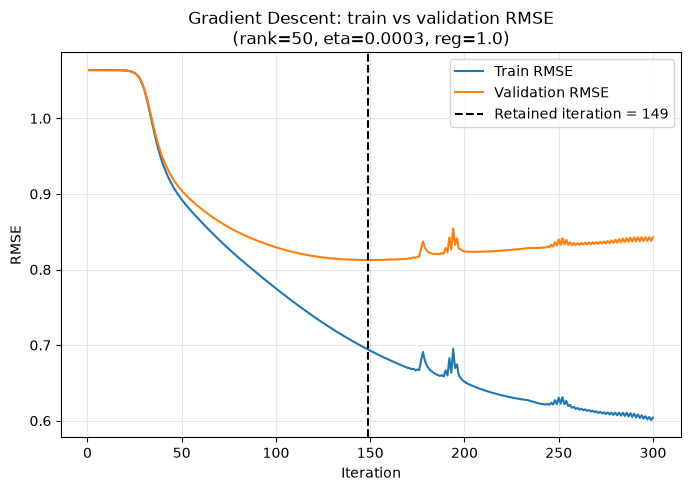

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(finalist_history["iteration"], finalist_history["train_rmse"], label="Train RMSE")
plt.plot(finalist_history["iteration"], finalist_history["val_rmse"], label="Validation RMSE")
plt.axvline(
    best_gd_n_iter,
    linestyle="--",
    color="black",
    label=f"Retained iteration = {best_gd_n_iter}",
)
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title(
    "Gradient Descent: train vs validation RMSE\n"
    f"(rank={best_gd_rank}, eta={best_gd_eta}, reg={best_gd_reg})"
)
plt.legend()
plt.grid(alpha=0.3)
plt.show()